<a href="https://colab.research.google.com/github/bhaktii1802/pytorch_fundamentals/blob/main/Lung_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import os
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, dataloader
import matplotlib.pyplot as plt

print("Torch:",  torch.__version__)
print("GPU available:", torch.cuda.is_available)

Torch: 2.14.1+cu130
GPU available: <function is_available at 0x7bb999945760>


In [7]:
from google.colab import files
files.upload()

Saving kaggle (1).json to kaggle (1).json


{'kaggle (1).json': b'{"username":"bhaktiselokar","key":"74ba4caf2c6f79c09c3e52b55cfc4b13"}'}

In [8]:
os.makedirs("root/kaggle", exist_ok = True)
!mv. kaggle.json/root/.kaggle/
!chmod 600/root/.kaggle/kaggle.json


/bin/bash: line 1: mv.: command not found
chmod: missing operand after ‘600/root/.kaggle/kaggle.json’
Try 'chmod --help' for more information.


In [12]:
!kaggle datasets download -d newra008/lung-mask-image-dataset
!ls

Dataset URL: https://www.kaggle.com/datasets/newra008/lung-mask-image-dataset
License(s): CC0-1.0
100% 2.59G/2.59G [00:40<00:00, 69.1MB/s]

'kaggle (1).json'   lung-mask-image-dataset.zip   root	 sample_data


In [13]:
!unzip -q lung-mask-image-dataset.zip -d /content/lung_data

In [14]:
for dp, dn, fn in os.walk("/content/lung_data"):
  if fn:
    print(dp, len(fn), fn[:2])

/content/lung_data/ChestXray/val/mask 2117 ['cxrmask_19098.jpeg', 'cxrmask_20715.jpeg']
/content/lung_data/ChestXray/val/image 2117 ['cxrimage_19048.png', 'cxrimage_20484.png']
/content/lung_data/ChestXray/test/mask 2116 ['cxrmask_18214.jpeg', 'cxrmask_17759.jpeg']
/content/lung_data/ChestXray/test/image 2116 ['cxrimage_17446.png', 'cxrimage_18430.png']
/content/lung_data/ChestXray/train/mask 16932 ['cxrmask_3685.jpeg', 'cxrmask_11069.jpeg']
/content/lung_data/ChestXray/train/image 16932 ['cxrimage_1012.png', 'cxrimage_15505.png']


In [20]:
import os, cv2, numpy as np, torch
from torch.utils.data import Dataset

class LungDataset(Dataset):
    def __init__(self, split_dir, img_size=(256, 256)):
        self.image_dir = os.path.join(split_dir, "image")
        self.mask_dir  = os.path.join(split_dir, "mask")
        self.img_size  = img_size
        self.filenames = sorted(os.listdir(self.image_dir))

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        name = self.filenames[idx]
        number = name.replace("cxrimage_", "").split(".")[0]
        mask_name = f"cxrmask_{number}.jpeg"

        image_path = os.path.join(self.image_dir, name)
        mask_path  = os.path.join(self.mask_dir, mask_name)

        image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
        mask  = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        if image is None:
            raise FileNotFoundError(f"Could not read image: {image_path}")
        if mask is None:
            raise FileNotFoundError(f"Could not read mask: {mask_path}")

        image = cv2.resize(image, self.img_size, interpolation=cv2.INTER_LINEAR)
        mask  = cv2.resize(mask,  self.img_size, interpolation=cv2.INTER_NEAREST)

        image = image.astype(np.float32) / 255.0
        mask  = (mask > 127).astype(np.float32)

        image = torch.from_numpy(image).unsqueeze(0)
        mask  = torch.from_numpy(mask).unsqueeze(0)
        return image, mask

In [21]:
base = "/content/lung_data/ChestXray"
train_ds = LungDataset(f"{base}/train")
val_ds   = LungDataset(f"{base}/val")
test_ds  = LungDataset(f"{base}/test")

img, mask = train_ds[0]
print(len(train_ds), len(val_ds), len(test_ds))
print(img.shape, mask.shape, mask.unique())

16932 2117 2116
torch.Size([1, 256, 256]) torch.Size([1, 256, 256]) tensor([0., 1.])


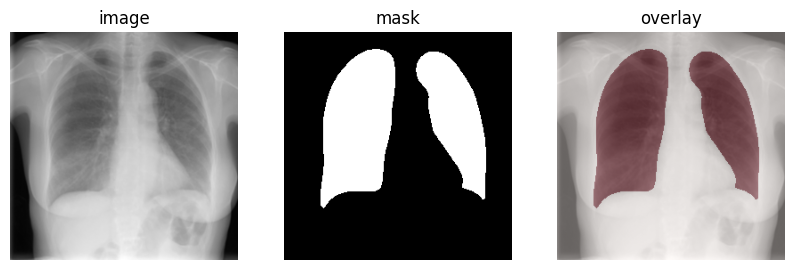

In [22]:
import matplotlib.pyplot as plt

img, mask = train_ds[0]
fig, ax = plt.subplots(1, 3, figsize=(10, 4))
ax[0].imshow(img[0], cmap="gray");  ax[0].set_title("image")
ax[1].imshow(mask[0], cmap="gray"); ax[1].set_title("mask")
ax[2].imshow(img[0], cmap="gray"); ax[2].imshow(mask[0], alpha=0.4, cmap="Reds"); ax[2].set_title("overlay")
for a in ax: a.axis("off")
plt.show()

In [24]:
from torch.utils.data import DataLoader
train_loader = DataLoader(train_ds, batch_size=16, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=16, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=16, shuffle=False, num_workers=2, pin_memory=True)

images, masks = next(iter(train_loader))
print(images.shape, masks.shape)

torch.Size([16, 1, 256, 256]) torch.Size([16, 1, 256, 256])


In [29]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)

In [30]:
x = torch.randn(1, 1, 256, 256)
print(DoubleConv(1, 64)(x).shape)

torch.Size([1, 64, 256, 256])


In [31]:
class UNet(nn.Module):
    def __init__(self, in_ch=1, out_ch=1, base=32):
        super().__init__()
        self.pool = nn.MaxPool2d(2)

        # Encoder
        self.enc1 = DoubleConv(in_ch,  base)
        self.enc2 = DoubleConv(base,   base*2)
        self.enc3 = DoubleConv(base*2, base*4)
        self.enc4 = DoubleConv(base*4, base*8)

        # Bottom
        self.bottleneck = DoubleConv(base*8, base*16)

        # Decoder
        self.up4  = nn.ConvTranspose2d(base*16, base*8, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(base*16, base*8)

        self.up3  = nn.ConvTranspose2d(base*8, base*4, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(base*8, base*4)

        self.up2  = nn.ConvTranspose2d(base*4, base*2, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(base*4, base*2)

        self.up1  = nn.ConvTranspose2d(base*2, base, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(base*2, base)

        # Final 1x1 conv: base channels -> 1 channel (lung or not)
        self.head = nn.Conv2d(base, out_ch, kernel_size=1)

    def forward(self, x):
        # Going down
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b  = self.bottleneck(self.pool(e4))

        # Going up
        d4 = self.up4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.head(d1)

In [32]:
model = UNet()
x = torch.randn(2, 1, 256, 256)
print(model(x).shape)
print(sum(p.numel() for p in model.parameters()) / 1e6, "million parameters")

torch.Size([2, 1, 256, 256])
7.765409 million parameters


In [33]:
import torch.nn as nn
import torch.nn.functional as F

class BCEDiceLoss(nn.Module):
    def __init__(self, smooth=1e-6):
        super().__init__()
        self.smooth = smooth
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)

        probs = torch.sigmoid(logits)
        # flatten each image so Dice is computed per image, then averaged
        probs   = probs.view(probs.size(0), -1)
        targets = targets.view(targets.size(0), -1)

        intersection = (probs * targets).sum(dim=1)
        dice = (2 * intersection + self.smooth) / (probs.sum(dim=1) + targets.sum(dim=1) + self.smooth)
        dice_loss = 1 - dice.mean()

        return bce_loss + dice_loss

In [34]:
@torch.no_grad()
def dice_iou(logits, targets, threshold=0.5, smooth=1e-6):
    preds   = (torch.sigmoid(logits) > threshold).float()
    preds   = preds.view(preds.size(0), -1)
    targets = targets.view(targets.size(0), -1)

    intersection = (preds * targets).sum(dim=1)
    union = preds.sum(dim=1) + targets.sum(dim=1) - intersection

    dice = (2 * intersection + smooth) / (preds.sum(dim=1) + targets.sum(dim=1) + smooth)
    iou  = (intersection + smooth) / (union + smooth)

    return dice.mean().item(), iou.mean().item()

In [35]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model = UNet().to(device)
criterion = BCEDiceLoss()

images, masks = next(iter(train_loader))
images, masks = images.to(device), masks.to(device)
logits = model(images)
print("loss:", criterion(logits, masks).item())
print("dice, iou:", dice_iou(logits, masks))

loss: 1.4056873321533203
dice, iou: (0.40704894065856934, 0.25738513469696045)


In [36]:
import time

def run_epoch(model, loader, criterion, optimizer=None):
    """Train if an optimizer is given, otherwise just evaluate."""
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss, total_dice, total_iou, n = 0.0, 0.0, 0.0, 0

    with torch.set_grad_enabled(training):
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)

            logits = model(images)
            loss = criterion(logits, masks)

            if training:
                optimizer.zero_grad()   # clear old gradients
                loss.backward()         # compute new gradients
                optimizer.step()        # update the weights

            bs = images.size(0)
            d, i = dice_iou(logits, masks)
            total_loss += loss.item() * bs
            total_dice += d * bs
            total_iou  += i * bs
            n += bs

    return total_loss / n, total_dice / n, total_iou / n


model = UNet().to(device)
criterion = BCEDiceLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)

EPOCHS = 10
best_dice = 0.0
history = {"train_loss": [], "val_loss": [], "val_dice": []}

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_dice, tr_iou = run_epoch(model, train_loader, criterion, optimizer)
    va_loss, va_dice, va_iou = run_epoch(model, val_loader, criterion)
    scheduler.step(va_dice)

    history["train_loss"].append(tr_loss)
    history["val_loss"].append(va_loss)
    history["val_dice"].append(va_dice)

    if va_dice > best_dice:
        best_dice = va_dice
        torch.save(model.state_dict(), "best_unet.pth")
        saved = "  <- saved"
    else:
        saved = ""

    print(f"Epoch {epoch:02d} | train loss {tr_loss:.4f} dice {tr_dice:.4f} | "
          f"val loss {va_loss:.4f} dice {va_dice:.4f} iou {va_iou:.4f} | "
          f"{time.time()-t0:.0f}s{saved}")

Epoch 01 | train loss 0.1385 dice 0.9596 | val loss 0.1076 dice 0.9592 iou 0.9248 | 403s  <- saved


KeyboardInterrupt: 

In [37]:
print(len(train_loader), len(val_loader))

1059 133


In [38]:
model.load_state_dict(torch.load("best_unet.pth"))
te_loss, te_dice, te_iou = run_epoch(model, test_loader, criterion)
print(f"TEST  loss {te_loss:.4f} | Dice {te_dice:.4f} | IoU {te_iou:.4f}")

TEST  loss 0.0384 | Dice 0.9850 | IoU 0.9711


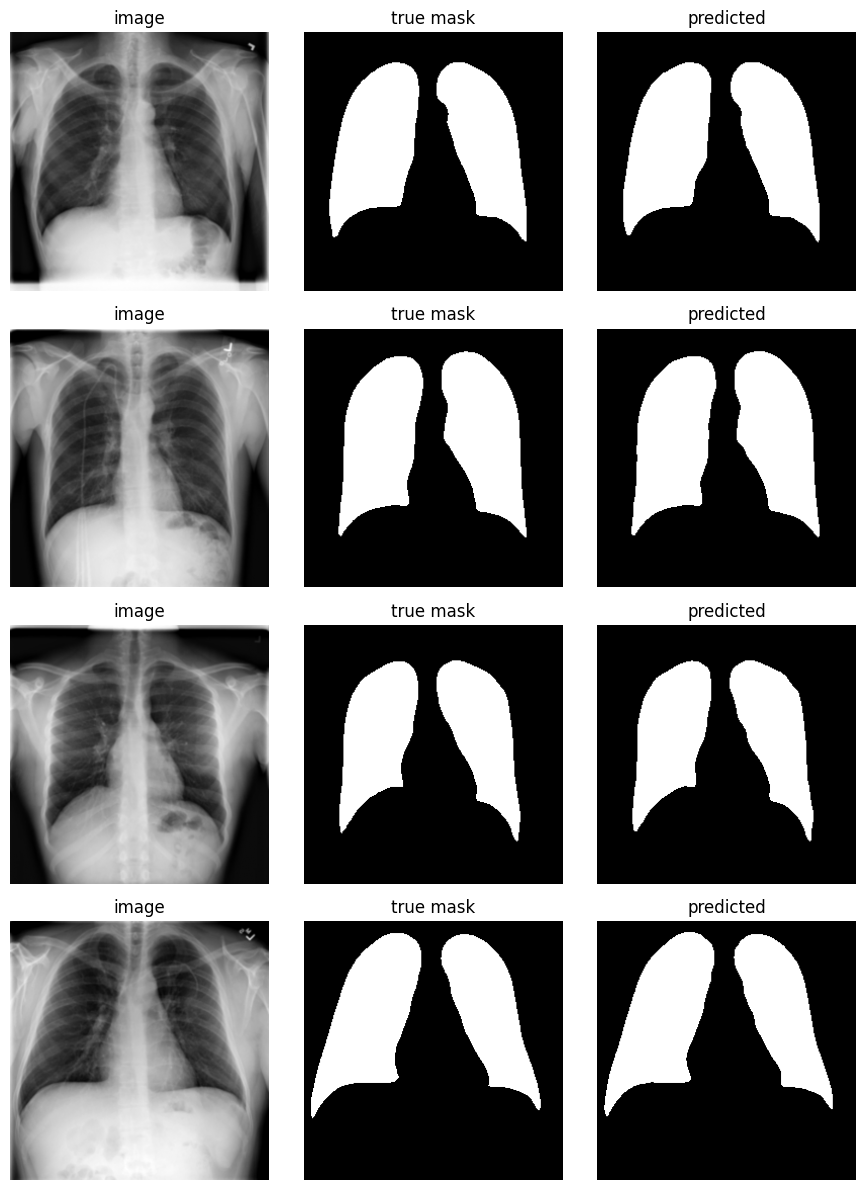

In [39]:
model.eval()
images, masks = next(iter(test_loader))
with torch.no_grad():
    preds = (torch.sigmoid(model(images.to(device))) > 0.5).float().cpu()

fig, ax = plt.subplots(4, 3, figsize=(9, 12))
for r in range(4):
    ax[r, 0].imshow(images[r, 0], cmap="gray"); ax[r, 0].set_title("image")
    ax[r, 1].imshow(masks[r, 0],  cmap="gray"); ax[r, 1].set_title("true mask")
    ax[r, 2].imshow(preds[r, 0],  cmap="gray"); ax[r, 2].set_title("predicted")
    for a in ax[r]: a.axis("off")
plt.tight_layout(); plt.show()

mean Dice: 0.9849689602851868
min Dice : 0.08931655436754227
images with Dice < 0.9: 12 of 2116


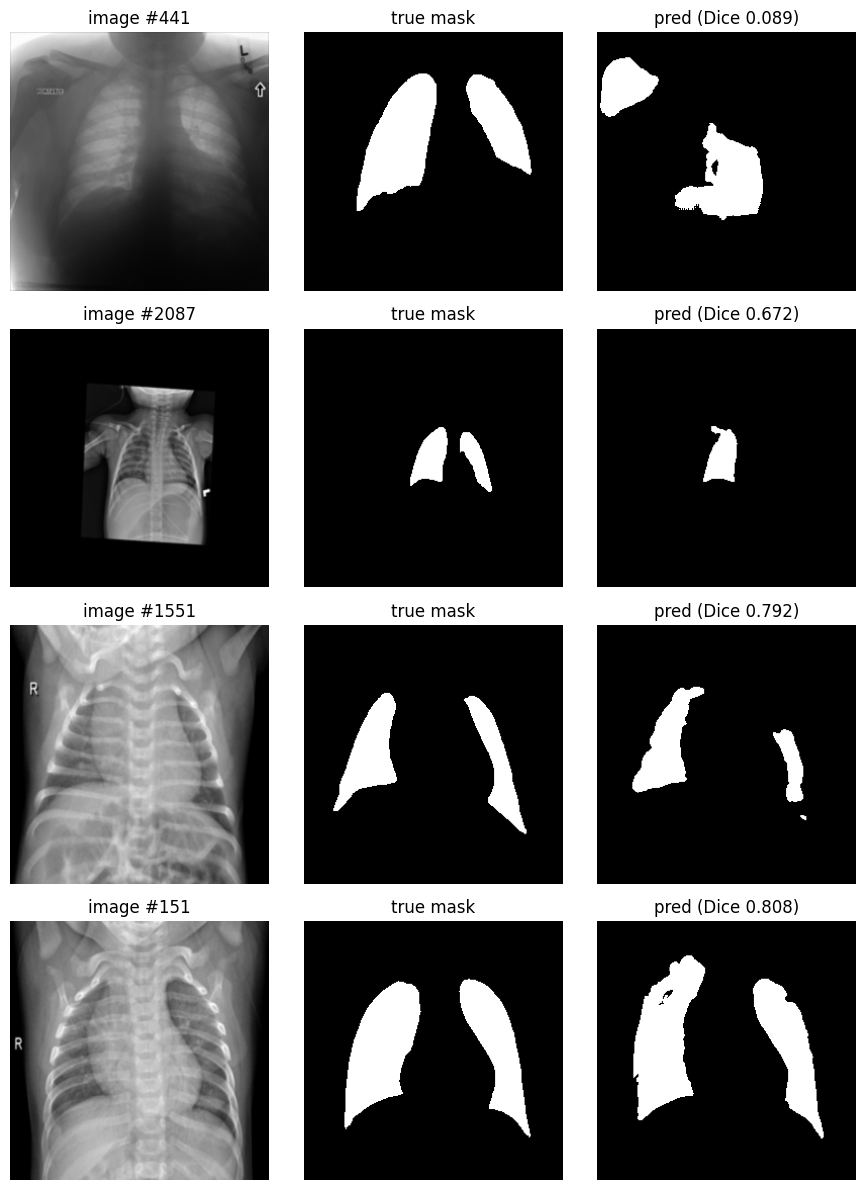

In [40]:
model.eval()
scores, all_imgs, all_masks, all_preds = [], [], [], []

with torch.no_grad():
    for images, masks in test_loader:
        logits = model(images.to(device))
        preds = (torch.sigmoid(logits) > 0.5).float().cpu()

        p = preds.view(preds.size(0), -1)
        t = masks.view(masks.size(0), -1)
        inter = (p * t).sum(dim=1)
        dice = (2 * inter + 1e-6) / (p.sum(dim=1) + t.sum(dim=1) + 1e-6)

        scores.extend(dice.tolist())
        all_imgs.append(images); all_masks.append(masks); all_preds.append(preds)

all_imgs  = torch.cat(all_imgs)
all_masks = torch.cat(all_masks)
all_preds = torch.cat(all_preds)
scores = torch.tensor(scores)

print("mean Dice:", scores.mean().item())
print("min Dice :", scores.min().item())
print("images with Dice < 0.9:", (scores < 0.9).sum().item(), "of", len(scores))

worst = scores.argsort()[:4]
fig, ax = plt.subplots(4, 3, figsize=(9, 12))
for r, i in enumerate(worst):
    ax[r, 0].imshow(all_imgs[i, 0],  cmap="gray"); ax[r, 0].set_title(f"image #{i.item()}")
    ax[r, 1].imshow(all_masks[i, 0], cmap="gray"); ax[r, 1].set_title("true mask")
    ax[r, 2].imshow(all_preds[i, 0], cmap="gray"); ax[r, 2].set_title(f"pred (Dice {scores[i]:.3f})")
    for a in ax[r]: a.axis("off")
plt.tight_layout(); plt.show()

In [41]:
import shutil
shutil.copy("best_unet.pth", "baseline_unet.pth")
torch.save(scores, "baseline_scores.pt")

In [43]:
from google.colab import drive
drive.mount('/content/drive')
CKPT = "/content/drive/MyDrive/best_unet_full.pth"

Mounted at /content/drive


In [44]:
print("device:", device)   # must say cuda

model = UNet().to(device)
criterion = BCEDiceLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)

EPOCHS = 8
best_dice = 0.0
history = {"train_loss": [], "val_loss": [], "train_dice": [], "val_dice": []}

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_dice, tr_iou = run_epoch(model, train_loader, criterion, optimizer)
    va_loss, va_dice, va_iou = run_epoch(model, val_loader, criterion)
    scheduler.step(va_dice)

    history["train_loss"].append(tr_loss); history["val_loss"].append(va_loss)
    history["train_dice"].append(tr_dice); history["val_dice"].append(va_dice)

    saved = ""
    if va_dice > best_dice:
        best_dice = va_dice
        torch.save(model.state_dict(), CKPT)
        saved = "  <- saved"

    lr = optimizer.param_groups[0]["lr"]
    print(f"Epoch {epoch:02d} | train loss {tr_loss:.4f} dice {tr_dice:.4f} | "
          f"val loss {va_loss:.4f} dice {va_dice:.4f} iou {va_iou:.4f} | "
          f"lr {lr:.1e} | {time.time()-t0:.0f}s{saved}")

device: cuda
Epoch 01 | train loss 0.1535 dice 0.9559 | val loss 0.1055 dice 0.9594 iou 0.9243 | lr 1.0e-03 | 410s  <- saved
Epoch 02 | train loss 0.0526 dice 0.9786 | val loss 0.0889 dice 0.9659 iou 0.9358 | lr 1.0e-03 | 403s  <- saved
Epoch 03 | train loss 0.0430 dice 0.9820 | val loss 0.1105 dice 0.9585 iou 0.9266 | lr 1.0e-03 | 404s
Epoch 04 | train loss 0.0381 dice 0.9839 | val loss 0.0806 dice 0.9687 iou 0.9421 | lr 1.0e-03 | 403s  <- saved
Epoch 05 | train loss 0.0355 dice 0.9850 | val loss 0.0806 dice 0.9693 iou 0.9426 | lr 1.0e-03 | 403s  <- saved
Epoch 06 | train loss 0.0347 dice 0.9853 | val loss 0.0628 dice 0.9753 iou 0.9529 | lr 1.0e-03 | 405s  <- saved
Epoch 07 | train loss 0.0318 dice 0.9865 | val loss 0.0598 dice 0.9765 iou 0.9554 | lr 1.0e-03 | 404s  <- saved
Epoch 08 | train loss 0.0290 dice 0.9876 | val loss 0.0588 dice 0.9774 iou 0.9571 | lr 1.0e-03 | 403s  <- saved
